# Notebook 02 - Linear Regression: predict the final score
**Question:** given homework, on-time submission, attendance and exercise, *what final score will a student get?*
The answer is a number (0-100), so this is a **regression** problem.

The model:
$$\hat{y} = b_0 + b_1 x_1 + b_2 x_2 + \dots + b_k x_k$$

**The optimization objective.** Training means choosing the $b$ values that make the **mean squared error** as small as possible:
$$\text{MSE}(b) = \frac{1}{n}\sum_{i=1}^{n} \left(y_i - \hat{y}_i\right)^2$$
This notebook opens up `fit()` so you can see that objective at work.

| Step | What |
|---|---|
| 1 | Load the data from notebook 01 |
| 2 | Simple linear regression: one feature, one line |
| 3 | **The objective:** MSE, the loss bowl, gradient descent by hand, and why outliers hurt |
| 4 | Baseline: always guess the average |
| 5 | Multiple linear regression and its coefficients |
| 6 | Evaluate on the test set (MAE, RMSE, R²) |
| 7 | Check the errors (residuals) |
| 8 | Which feature matters most? |
| 9 | Predict new students |

## Step 1 - Load the processed data

In [325]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "make_data.py").exists())
sys.path.append(str(ROOT))
from src.quiz import check, summary
DATA = ROOT / "data"
assert (DATA / "train_processed.csv").exists(), "Run notebook 01 first!"
plt.rcParams["figure.dpi"] = 110

prep = joblib.load(DATA / "preprocessing.joblib")
FEATURES, TARGET = prep["features"], "final_score"
missing = sorted(set(range(1, 10)) - set(prep["patches"]))
if missing:
    print(f"⚠️  Notebook 01 was saved WITHOUT patches {missing}. Everything below still runs,")
    print("    but your numbers will be worse than the ones described in the text. Finish notebook 01 first!\n")

train = pd.read_csv(DATA / "train_processed.csv")
test = pd.read_csv(DATA / "test_processed.csv")
X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
print("features:", FEATURES)
print("train:", X_train.shape, " test:", X_test.shape)

features: ['hw_avg', 'on_time_rate', 'midterm_attendance', 'final_attendance', 'exercises', 'section_B', 'section_C']
train: (320, 7)  test: (80, 7)


## Step 2 - Simple linear regression: one feature
Start with the single strongest feature, `hw_avg`: $\hat{y} = b_0 + b_1 \cdot hw\_avg$

final_score = 36.05 + 6.54 x hw_avg


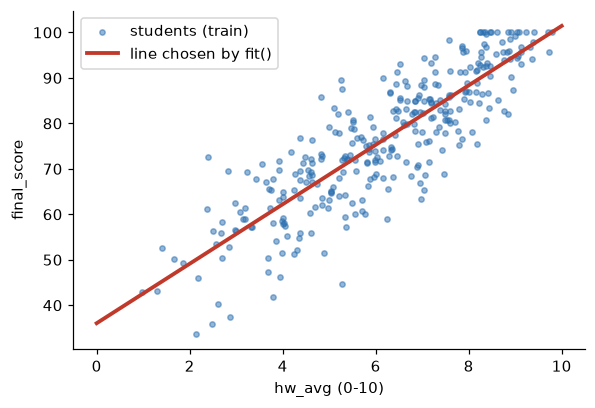

In [326]:
simple = LinearRegression().fit(X_train[["hw_avg"]], y_train)
b0_best, b1_best = simple.intercept_, simple.coef_[0]
print(f"final_score = {b0_best:.2f} + {b1_best:.2f} x hw_avg")

xs = np.linspace(0, 10, 50)
plt.figure(figsize=(6, 4))
plt.scatter(X_train["hw_avg"], y_train, s=12, alpha=0.5, color="#2a6fb0", label="students (train)")
plt.plot(xs, b0_best + b1_best * xs, color="#c0392b", lw=2.5, label="line chosen by fit()")
plt.xlabel("hw_avg (0-10)"); plt.ylabel("final_score"); plt.legend()
plt.gca().spines[["top", "right"]].set_visible(False); plt.show()

**Why this line and not another one?** That is what Step 3 is about.

## Step 3 - The objective: least squares
### 3a. Score some candidate lines
For any line we can compute its **MSE** on the training students. `fit()` returns the line with the **lowest** MSE of all possible lines.

In [327]:
x, y = X_train["hw_avg"].values, y_train.values

def mse(b0, b1):
    errors = y - (b0 + b1 * x)          # actual - predicted, for every student
    return np.mean(errors ** 2)         # square, then average

candidates = {"flat line at the average": (y.mean(), 0.0),
              "my guess A": (50, 4.0),
              "my guess B": (20, 9.0),
              "fit()": (b0_best, b1_best)}
pd.DataFrame([(name, b0, b1, mse(b0, b1)) for name, (b0, b1) in candidates.items()],
             columns=["line", "b0", "b1", "MSE"]).round(2)

,line,b0,b1,MSE
0,flat line at the average,76.38,0.00,210.65
1,my guess A,50.00,4.00,81.69
2,my guess B,20.00,9.00,78.12
3,fit(),36.05,6.54,55.35


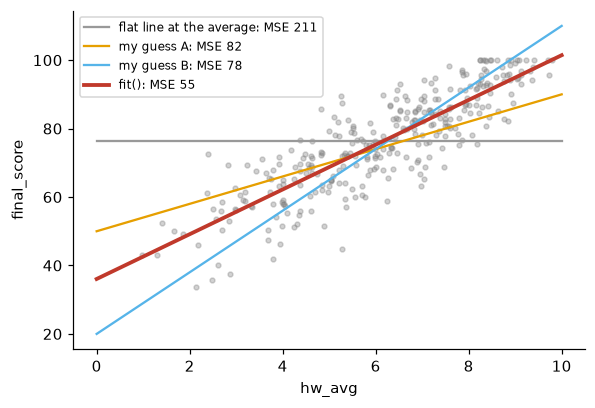

In [328]:
plt.figure(figsize=(6, 4))
plt.scatter(x, y, s=10, alpha=0.35, color="gray")
for (name, (b0, b1)), c in zip(candidates.items(), ["#999999", "#e69f00", "#56b4e9", "#c0392b"]):
    plt.plot(xs, b0 + b1 * xs, lw=2.5 if name == "fit()" else 1.5, color=c, label=f"{name}: MSE {mse(b0, b1):.0f}")
plt.xlabel("hw_avg"); plt.ylabel("final_score"); plt.legend(fontsize=8)
plt.gca().spines[["top", "right"]].set_visible(False); plt.show()

> ### Checkpoint O1
> What exactly does `LinearRegression.fit()` choose $b_0, b_1, \dots$ to minimize?
>
> **A)** the sum of the absolute errors |y - ŷ|  
> **B)** the mean (or sum) of the squared errors (y - ŷ)²  
> **C)** the number of students predicted wrong  
> **D)** the single largest error  


In [329]:
check("O1", 'B')   # <- replace ? with your answer

[O1] Correct!
  Why: Ordinary least squares picks b0..bk to minimize the mean (or sum) of squared errors, MSE = mean((y - y_hat)^2).


> ### Checkpoint O2
> Three students have actual scores **80, 60, 90**. A model predicts **75, 65, 90**. What is the MSE? (Work it out by hand; you can use the empty cell below as a calculator.)
>
> *Answer with a number (2 decimals are enough).*


In [330]:
check("O2", '16.67')   # <- replace ? with your answer

[O2] Correct!
  Why: (25 + 25 + 0) / 3 = 16.67. Note the sign of an error disappears when squared.


### 3b. Optimization (optional knowledge point to grasp)
Keep $b_0$ at its best value and try many slopes $b_1$. Plot the MSE for each one.

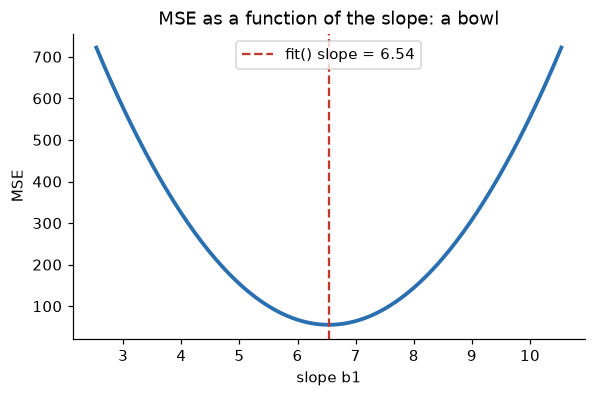

In [331]:
slopes = np.linspace(b1_best - 4, b1_best + 4, 200)
plt.figure(figsize=(6, 3.6))
plt.plot(slopes, [mse(b0_best, s) for s in slopes], color="#2a6fb0", lw=2.5)
plt.axvline(b1_best, color="#c0392b", ls="--", label=f"fit() slope = {b1_best:.2f}")
plt.xlabel("slope b1"); plt.ylabel("MSE"); plt.title("MSE as a function of the slope: a bowl")
plt.legend(); plt.gca().spines[["top", "right"]].set_visible(False); plt.show()

> ### Checkpoint O4
> The MSE of a linear model is a **bowl** (convex): it has one lowest point. Why is that good news for training?
>
> **A)** There is a single minimum, so any path that keeps going downhill (like gradient descent) ends at the same best line  
> **B)** It means the MSE is always zero  
> **C)** It proves the data is perfectly linear  
> **D)** It makes R² equal to 1  


In [332]:
check("O4", 'A')   # <- replace ? with your answer

[O4] Correct!
  Why: The MSE of a linear model is convex (a bowl): one minimum, no false valleys. Any downhill path, like gradient descent, ends at the same best line sklearn finds.


### 3c. Gradient descent by hand
`scikit-learn` solves least squares with linear algebra in one shot. Most of machine learning (logistic regression, neural networks) instead uses **gradient descent**: start somewhere, then repeatedly take a small step **downhill**.

For our line, the slopes of the bowl (the gradient) are
$$\frac{\partial\,\text{MSE}}{\partial b_0} = -\frac{2}{n}\sum (y_i - \hat{y}_i), \qquad \frac{\partial\,\text{MSE}}{\partial b_1} = -\frac{2}{n}\sum (y_i - \hat{y}_i)\,x_i$$
and each step is $b \leftarrow b - \text{lr} \times \text{gradient}$, where **lr** is the *learning rate* (step size).

In [333]:
def gradient_descent(lr, steps=3000, b0=0.0, b1=0.0):
    path, losses = [(b0, b1)], [mse(b0, b1)]
    for _ in range(steps):
        errors = y - (b0 + b1 * x)
        grad_b0 = -2 * errors.mean()
        grad_b1 = -2 * (errors * x).mean()
        b0, b1 = b0 - lr * grad_b0, b1 - lr * grad_b1        # one step downhill
        path.append((b0, b1)); losses.append(mse(b0, b1))
        if not np.isfinite(losses[-1]) or losses[-1] > 1e8:  # stop if it blows up 1e8 is what we call a very small threshold
            break
    return np.array(path), np.array(losses)

lr = 0.0234 # try 0.005, 0.02, then 0.025
path, losses = gradient_descent(lr)
print(f"after {len(losses) - 1} steps: b0 = {path[-1, 0]:.2f}, b1 = {path[-1, 1]:.2f}, MSE = {losses[-1]:.2f}")
print(f"fit() answer:      b0 = {b0_best:.2f}, b1 = {b1_best:.2f}, MSE = {mse(b0_best, b1_best):.2f}")

after 3000 steps: b0 = 36.05, b1 = 6.54, MSE = 55.35
fit() answer:      b0 = 36.05, b1 = 6.54, MSE = 55.35


In [334]:
minimum = mse(b0_best, b1_best)

for step, loss in enumerate(losses):
    if loss <= minimum + 1:
        print("Steps needed:", step)
        break
else:
    print("Needs more than 3000 steps")

Steps needed: 680


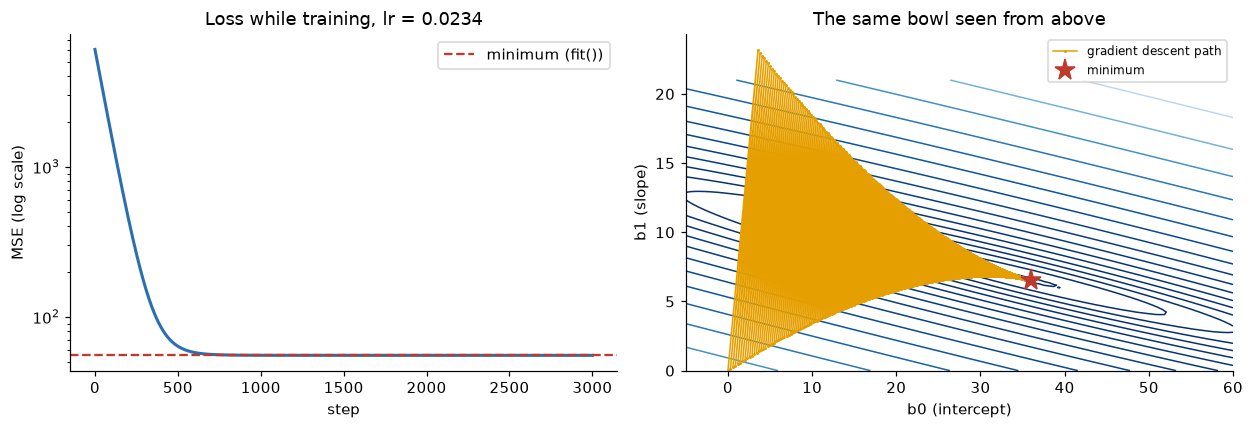

In [335]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
axes[0].plot(losses, color="#2a6fb0", lw=2)
axes[0].axhline(mse(b0_best, b1_best), color="#c0392b", ls="--", label="minimum (fit())")
axes[0].set_yscale("log"); axes[0].set_xlabel("step"); axes[0].set_ylabel("MSE (log scale)")
axes[0].set_title(f"Loss while training, lr = {lr}"); axes[0].legend()

B0, B1 = np.meshgrid(np.linspace(-5, 60, 120), np.linspace(0, 21, 120))
J = np.mean((y[None, None, :] - (B0[..., None] + B1[..., None] * x[None, None, :])) ** 2, axis=2)
axes[1].contour(B0, B1, J, levels=np.geomspace(J.min() * 1.02, J.max(), 18), cmap="Blues_r", linewidths=1)
shown = path[np.isfinite(path).all(axis=1) & (np.abs(path) < 100).all(axis=1)]
axes[1].plot(shown[:, 0], shown[:, 1], ".-", color="#e69f00", ms=2, lw=1, label="gradient descent path")
axes[1].plot(b0_best, b1_best, "*", color="#c0392b", ms=14, label="minimum")
axes[1].set_xlabel("b0 (intercept)"); axes[1].set_ylabel("b1 (slope)")
axes[1].set_title("The same bowl seen from above"); axes[1].legend(fontsize=8)
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Notice:** the bowl is a long, narrow valley, so the path first rushes down the steep side and then crawls along the valley floor. That shape comes from features that are not centered or scaled - notebook 03 shows how scaling fixes it.

**Try it:** change `lr` to `0.005` (what happens to speed?) and to `0.025` (what happens to the loss?).

> ### Checkpoint O3
> What happens in gradient descent when the learning rate is **too large**?
>
> **A)** It is slower but always safe  
> **B)** Each step overshoots the bottom, so the loss bounces around or grows without limit (diverges)  
> **C)** It finds a better minimum than fit()  
> **D)** Nothing changes  


In [336]:
check("O3", 'B')   # <- replace ? with your answer

[O3] Correct!
  Why: Each step overshoots the bottom of the bowl by more than it started, so the loss grows without limit (divergence). Too small a learning rate is safe but slow.


### 3d. Why preprocessing matters for this objective
Remember Patch 5 (outliers)? Suppose one student's homework average had been ruined by a typo (one homework typed as 99 instead of 9.9), giving `hw_avg` = 22. Watch what **one** bad row does to the least-squares line.

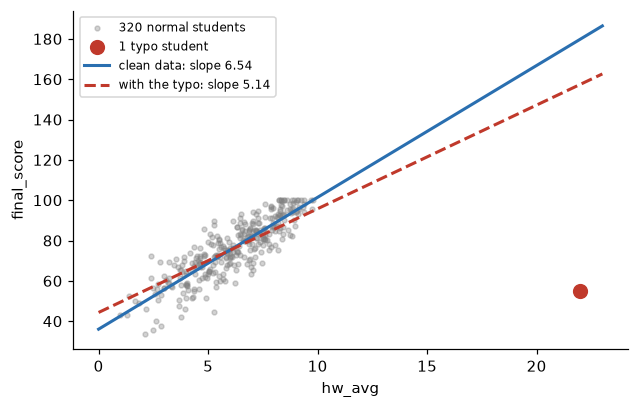

One row out of 321 changed the slope by -21%.


In [337]:
x_bad = np.append(x, 22.0)          # one typo student
y_bad = np.append(y, 55.0)
b1_bad, b0_bad = np.polyfit(x_bad, y_bad, 1)

xs2 = np.linspace(0, 23, 50)
plt.figure(figsize=(6.5, 4))
plt.scatter(x, y, s=10, alpha=0.35, color="gray", label="320 normal students")
plt.scatter([22], [55], s=80, color="#c0392b", label="1 typo student")
plt.plot(xs2, b0_best + b1_best * xs2, color="#2a6fb0", lw=2, label=f"clean data: slope {b1_best:.2f}")
plt.plot(xs2, b0_bad + b1_bad * xs2, color="#c0392b", lw=2, ls="--", label=f"with the typo: slope {b1_bad:.2f}")
plt.xlabel("hw_avg"); plt.ylabel("final_score"); plt.legend(fontsize=8)
plt.gca().spines[["top", "right"]].set_visible(False); plt.show()
print(f"One row out of 321 changed the slope by {100 * (b1_bad - b1_best) / b1_best:.0f}%.")

Squaring the error makes the single huge miss on the typo student weigh as much as many normal students together, so the line tilts toward it. **Cleaning data protects the objective.**

## Step 4 - Baseline: always guess the average
Every model needs something to beat. The "flat line" from Step 3a predicts the class average for everyone.

In [338]:
baseline_pred = np.full(len(y_test), y_train.mean())
print(f"Baseline guess for everyone: {y_train.mean():.1f}")
print(f"Baseline MAE : {mean_absolute_error(y_test, baseline_pred):.2f} points")
print(f"Baseline R²  : {r2_score(y_test, baseline_pred):.3f}  (about 0 by definition)")

Baseline guess for everyone: 76.4
Baseline MAE : 12.11 points
Baseline R²  : -0.001  (about 0 by definition)


## Step 5 - Adding features
Same objective (MSE), now with all features at once. Read each coefficient as: *"if this feature goes up by 1 and everything else stays the same, the predicted final score changes by b points."*

In [339]:

lin = LinearRegression().fit(X_train, y_train)

meaning = {"hw_avg": "per +1 homework point (out of 10)",
           "on_time_rate": "from 0% to 100% of homework on time",
           "midterm_attendance": "from 0% to 100% attendance before midterm",
           "final_attendance": "from 0% to 100% attendance after midterm",
           "exercises": "exercises regularly vs not",
           "section_B": "section B vs section A",
           "section_C": "section C vs section A"}
coef = pd.DataFrame({"feature": FEATURES, "coefficient": lin.coef_.round(2)})
coef["read it as: change in final score ..."] = coef["feature"].map(meaning).fillna("")
print(f"intercept b0 = {lin.intercept_:.2f}   training MSE = {mean_squared_error(y_train, lin.predict(X_train)):.2f}")
coef

intercept b0 = 18.09   training MSE = 34.14


,feature,coefficient,read it as: change in final score ...
0,hw_avg,3.38,per +1 homework point (out of 10)
1,on_time_rate,8.35,from 0% to 100% of homework on time
2,midterm_attendance,22.71,from 0% to 100% attendance before midterm
3,final_attendance,15.12,from 0% to 100% attendance after midterm
4,exercises,4.13,exercises regularly vs not
5,section_B,0.56,section B vs section A
6,section_C,0.27,section C vs section A


> ### Checkpoint O6
> The coefficient of `hw_avg` is about **3.4**. Which reading is correct?
>
> **A)** Each extra homework point (out of 10) predicts about 3.4 more final-score points, with the other features held fixed  
> **B)** Homework is 3.4 times more important than any other feature  
> **C)** Homework explains 3.4% of the final score  
> **D)** A student needs 3.4 homework points to pass  


In [340]:
check("O6", 'A')   # <- replace ? with your answer

[O6] Correct!
  Why: +1 homework point (out of 10) -> about +3.4 predicted final points, with attendance, on-time rate, etc. unchanged. Unscaled coefficients are in real units and cannot be compared with each other for importance.


## Step 6 - Evaluate on the test set
| Metric | Meaning | Better |
|---|---|---|
| **MAE** | average size of the error, in points | lower |
| **RMSE** | square root of MSE (our training objective!), in points | lower |
| **R²** | $1 - \frac{\text{SSE}_{model}}{\text{SSE}_{baseline}}$: share of the baseline's squared error the model removes | higher |

In [341]:
y_pred = lin.predict(X_test)
pred_simple = simple.predict(X_test[["hw_avg"]])

def scores(y_true, y_hat):
    return {"MAE": mean_absolute_error(y_true, y_hat),
            "RMSE": mean_squared_error(y_true, y_hat) ** 0.5,
            "R2": r2_score(y_true, y_hat)}

pd.DataFrame({"baseline (average)": scores(y_test, baseline_pred),
              "simple (hw_avg only)": scores(y_test, pred_simple),
              "multiple (all features)": scores(y_test, y_pred)}).T.round(3)

,MAE,RMSE,R2
baseline (average),12.109,15.157,-0.001
simple (hw_avg only),5.920,7.298,0.768
multiple (all features),4.542,5.396,0.873


In [342]:
print(f"R² train = {r2_score(y_train, lin.predict(X_train)):.3f}   R² test = {r2_score(y_test, y_pred):.3f}")
print("Close numbers -> the model is not overfitting.")

R² train = 0.838   R² test = 0.873
Close numbers -> the model is not overfitting.


> ### Checkpoint O5
> The multiple model has test **R² ≈ 0.87**. What does that mean?
>
> **A)** 87% of the predictions are exactly right  
> **B)** The model removes about 87% of the squared error that 'always guess the average' would make  
> **C)** The average error is 13 points  
> **D)** 87% of students pass  


In [343]:
check("O5", 'B')   # <- replace ? with your answer

[O5] Correct!
  Why: R2 = 1 - SSE_model / SSE_baseline. 0.87 means the model removes 87% of the squared error that guessing the class average would make. It is not a percent of exact hits.


## Step 7 - Check the errors (residuals)
Residual = actual - predicted. Good residuals look like random noise around 0.

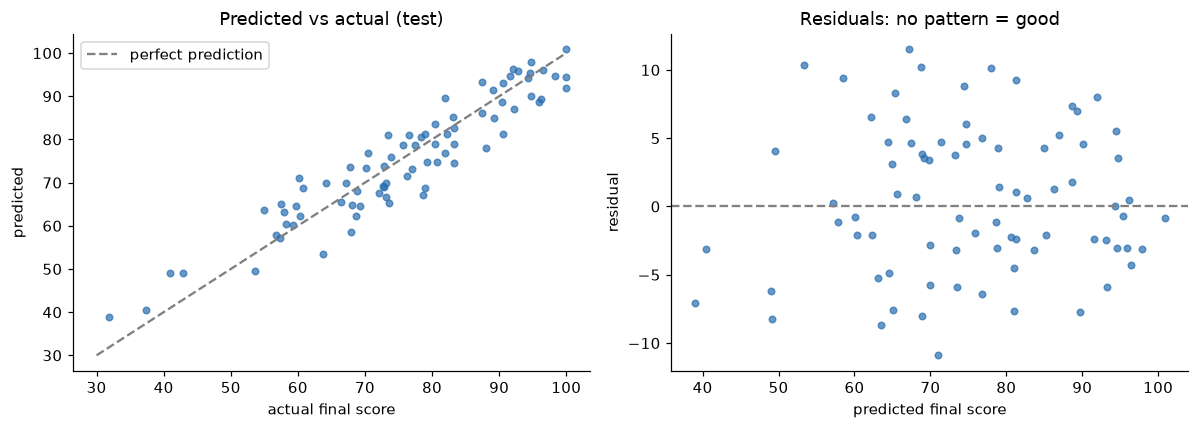

In [344]:
resid = y_test - y_pred
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, y_pred, s=18, alpha=0.7, color="#2a6fb0")
axes[0].plot([30, 100], [30, 100], "--", color="gray", label="perfect prediction")
axes[0].set_xlabel("actual final score"); axes[0].set_ylabel("predicted"); axes[0].legend()
axes[0].set_title("Predicted vs actual (test)")
axes[1].scatter(y_pred, resid, s=18, alpha=0.7, color="#2a6fb0"); axes[1].axhline(0, color="gray", ls="--")
axes[1].set_xlabel("predicted final score"); axes[1].set_ylabel("residual"); axes[1].set_title("Residuals: no pattern = good")
for ax in axes: ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## Step 8 - Which feature matters most?
Unscaled coefficients can't be compared (`hw_avg` goes 0-10, attendance 0-1). Fit the same model on the **scaled** data: each coefficient now means *"points per one standard deviation."*

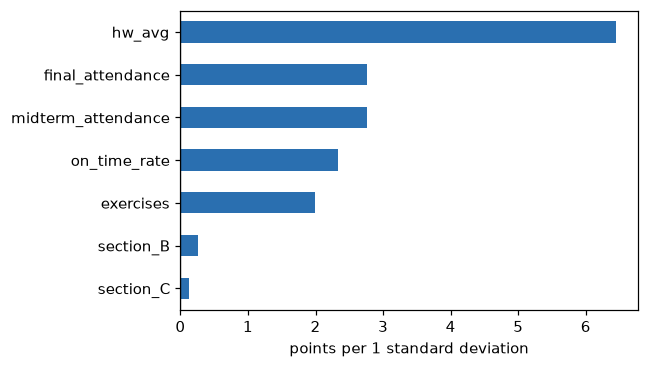

Same predictions as the unscaled model? True


In [345]:
train_s = pd.read_csv(DATA / "train_scaled.csv")
lin_s = LinearRegression().fit(train_s[FEATURES], train_s[TARGET])
imp = pd.Series(lin_s.coef_, index=FEATURES).sort_values()
ax = imp.plot.barh(figsize=(6, 0.35 * len(imp) + 1), color=["#c0392b" if v < 0 else "#2a6fb0" for v in imp])
ax.axvline(0, color="k", lw=0.8); ax.set_xlabel("points per 1 standard deviation")
plt.tight_layout(); plt.show()
print("Same predictions as the unscaled model?", np.allclose(lin_s.predict(pd.read_csv(DATA / "test_scaled.csv")[FEATURES]), y_pred))

### Reveal: how the data was made
`final = 18 + 3.2·hw_avg + 10·on_time_rate + 22·midterm_att + 16·final_att + 4·exercises + noise` (section and seat row: **no effect**)

In [346]:
truth = pd.Series({"hw_avg": 3.2, "on_time_rate": 10, "midterm_attendance": 22,
                   "final_attendance": 16, "exercises": 4, "section_B": 0, "section_C": 0})
pd.DataFrame({"true": truth, "learned": pd.Series(lin.coef_, index=FEATURES).round(2)})

,true,learned
hw_avg,3.2,3.38
on_time_rate,10.0,8.35
midterm_attendance,22.0,22.71
final_attendance,16.0,15.12
exercises,4.0,4.13
section_B,0.0,0.56
section_C,0.0,0.27


Why are the two attendance coefficients the least accurate? (Hint: they are 0.87 correlated with each other, so the objective can trade one for the other with almost no change in MSE.)

## Step 9 - Predict new students

In [347]:
new_students = pd.DataFrame([
    {"hw_avg": 8.5, "on_time_rate": 1.00, "midterm_attendance": 0.95, "final_attendance": 0.90, "exercises": 1, "section_B": 0, "section_C": 0},
    {"hw_avg": 8.5, "on_time_rate": 1.00, "midterm_attendance": 0.95, "final_attendance": 0.50, "exercises": 1, "section_B": 0, "section_C": 0},
    {"hw_avg": 7.2, "on_time_rate": 0.33, "midterm_attendance": 0.70, "final_attendance": 0.55, "exercises": 0, "section_B": 1, "section_C": 0},

    
]).reindex(columns=FEATURES, fill_value=0)
new_students["predicted_final"] = lin.predict(new_students[FEATURES]).round(1)
new_students

,hw_avg,on_time_rate,midterm_attendance,final_attendance,exercises,section_B,section_C,predicted_final
0,8.5,1.00,0.95,0.90,1,0,0,94.5
1,8.5,1.00,0.95,0.50,1,0,0,88.5
2,7.2,0.33,0.70,0.55,0,1,0,70.0


In [348]:
joblib.dump(lin, DATA / "linear_model.joblib")
summary("O")

Correct: 6 / 6   O1 O2 O3 O4 O5 O6


## Your turn
1. **Objective:** in Step 3c, how many steps does `lr = 0.005` need to get within 1 MSE point of the minimum? Find the largest `lr` that still works.
2715 setps using a lr of 0.005. The largest r that works is 0.0234 since that converges to 55.35 while 0.0235 diverges to about 1 billion
2. Add a "perfect" student (hw_avg 10, everything else at its maximum) to Step 9. The model predicts **above 100**. Why does least squares allow that, and what could you do about it?
since our code is linear regression, it is based off an equation that has no cap so it can go past 100 easily. to combat this we could cap teh equation at 100.
3. Drop `section_B` and `section_C` from `FEATURES` and refit. Does test R² go down? What does that tell you about feature selection?
Removing sectionB and sectionC made the R2 approximately 0.873. removing the sections did almost nothing to the r2 and shows that not all feature selection improves a model
4. Fit the model with `midterm_attendance` and `final_attendance`. An advisor wants to use it at the midterm - which feature is a problem, and why?
The feature that is a problem is final attendance since it is in the future and not known by the midterm
5. Change student 3 in Step 9 so the model predicts at least 70. What is the smallest single change that does it?
Homework average requires the smallest percentage change to reach 70 going from 5.0 to 7.2 
**Next:** `03_logistic_regression.ipynb` - instead of the score, predict **pass / fail** with a different objective.